# PyTorch: от тензоров до обучения нейросетей

- Документация: https://pytorch.org/docs/stable/
- Туториалы: https://pytorch.org/tutorials/
- Форум: https://discuss.pytorch.org/
- Установка: https://pytorch.org/get-started/locally/

## План

1. **Тензоры**: создание, операции, `dtype`, GPU (`cuda` / `mps`), broadcasting, `einsum`
2. **Autograd**: вычислительный граф, `backward`, кастомные `autograd.Function`, производные высших порядков
3. **Распределения** `torch.distributions`: сэмплирование, `log_prob`, KL и оптимизация через неё
4. **Нейросети** `torch.nn`: `nn.Module`, `nn.Parameter`, контейнеры
5. **Обучение**: loss, optimizer, цикл обучения, `Dataset` / `DataLoader`, train / val
6. **Режимы модели**: `Dropout`, `BatchNorm`, `train()` / `eval()`, `no_grad` / `inference_mode`
7. **Предсказание неопределённости**: гауссовская голова (NLL) и MC Dropout

In [ ]:
# Установка необходимых библиотек
# conda create -n deeplearn numpy matplotlib pip ipykernel
# conda activate deeplearn
# conda install cuda -c nvidia/label/cuda-12.6.0
# pip3 install torch torchvision --index-url https://download.pytorch.org/whl/cu126 

In [1]:
import time
import timeit
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, TensorDataset, DataLoader

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.14.0+cu126
CUDA available:  True
MPS available:   False


---
# 1. Тензоры

## 1.1 Создание и базовые операции

`torch.Tensor` — аналог `np.ndarray`, но умеет жить на GPU и считать градиенты.

In [20]:
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([4.0, 5.0, 6.0])

print('a + b:', a + b)
print('a * b:', a * b)   # поэлементно
print('a @ b:', a @ b)   # скалярное произведение для векторов

a + b: tensor([5., 7., 9.])
a * b: tensor([ 4., 10., 18.])
a @ b: tensor(32.)


In [21]:
torch.allclose(a @ b, torch.dot(a, b))

True

In [4]:
matrix = torch.rand(3, 4)
print(matrix.shape)
print(matrix.size(0), matrix.size(-1))
print(matrix)

torch.Size([3, 4])
3 4
tensor([[0.6036, 0.2234, 0.8696, 0.9076],
        [0.9110, 0.5544, 0.8561, 0.3454],
        [0.5017, 0.0158, 0.5556, 0.5543]])


In [6]:
# Полезные конструкторы
print(torch.zeros(2, 3))
print(torch.ones(2, 3))
print(torch.arange(6).reshape(2, 3))
print(torch.randn(2, 3))  # N(0, 1)

# Мост с numpy
arr = np.array([1, 2, 3])
t = torch.from_numpy(arr)
print(t, t.numpy())

tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[0, 1, 2],
        [3, 4, 5]])
tensor([[-0.8742,  0.0857,  1.7941],
        [-1.3066,  0.9483,  0.8708]])
tensor([1, 2, 3]) [1 2 3]


### dtype

По умолчанию float-тензоры — `float32`. Это важно: у fp32 меньше диапазон и точность, чем у fp64 из numpy.

In [7]:
a = torch.tensor([1e20, 1e20])
print(a.dtype)
print('Norm (fp32):', a.norm())           # переполнение -> inf
print('Norm (fp64):', a.double().norm())

a = torch.tensor(1e5)
print('Before:', a.dtype)
a = a.to(torch.float64)                   # то же, что a.double() или a.type(torch.float64)
print('After: ', a.dtype)

torch.float32
Norm (fp32): tensor(inf)
Norm (fp64): tensor(1.4142e+20, dtype=torch.float64)
Before: torch.float32
After:  torch.float64


## 1.2 Вычисления на GPU

- `cuda` — видеокарты NVIDIA
- `mps` — Apple Silicon (Metal Performance Shaders)
- `cpu` — всё остальное

Удобно один раз выбрать `device` и дальше писать код, не зависящий от железа.

In [28]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def synchronize(device):
    # GPU работает асинхронно: ждём, пока все запущенные ядра досчитаются
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps':
        torch.mps.synchronize()


device = get_device()
device

device(type='cuda')

In [9]:
if torch.cuda.is_available():
    print(torch.cuda.device_count())          # количество GPU
    print(torch.cuda.current_device())        # индекс текущего GPU
    print(torch.cuda.get_device_name(0))      # название GPU
    print(torch.cuda.memory_allocated(0))     # занятая тензорами память (bytes)
    print(torch.cuda.memory_reserved(0))      # зарезервированная аллокатором память
    print(torch.cuda.mem_get_info(0))         # (свободно, всего)

# Ещё полезное:
# torch.cuda.max_memory_allocated(0)   # пиковое использование
# torch.cuda.empty_cache()             # отдать кэш аллокатора обратно драйверу
# torch.cuda.memory_summary()          # подробная статистика
# !nvidia-smi                          # из терминала / ноутбука

1
0
NVIDIA GeForce RTX 3090
0
0
(24465375232, 25769279488)


In [10]:
matrix = torch.rand(3, 4)
matrix_gpu = matrix.to(device)

print(f'CPU tensor device: {matrix.device}')
print(f'GPU tensor device: {matrix_gpu.device}')

CPU tensor device: cpu
GPU tensor device: cuda:0


### CPU vs GPU: перемножение больших матриц

In [11]:
n = 4096
a_cpu = torch.randn(n, n)
b_cpu = torch.randn(n, n)

cpu_time = min(timeit.repeat(lambda: a_cpu @ b_cpu, number=1, repeat=3))
print(f'CPU time: {cpu_time:.4f} s')

CPU time: 0.1882 s


In [12]:
a_gpu = a_cpu.to(device)
b_gpu = b_cpu.to(device)
a_gpu @ b_gpu  # прогрев
synchronize(device)

gpu_time = min(timeit.repeat(lambda: a_gpu @ b_gpu, number=1, repeat=3))
print(f'GPU time (без synchronize): {gpu_time:.4f} s  -> speedup {cpu_time / gpu_time:.1f}x')

GPU time (без synchronize): 0.0000 s  -> speedup 15180.3x


Такое ускорение подозрительно большое: вызов на GPU **асинхронный**, Python получает управление сразу, как только ядро поставлено в очередь.
Чтобы честно замерить время, нужно дождаться окончания вычислений — `synchronize`.

In [13]:
def matmul_sync():
    a_gpu @ b_gpu
    synchronize(device)

gpu_time = min(timeit.repeat(matmul_sync, number=1, repeat=3))
print(f'GPU time (с synchronize):   {gpu_time:.4f} s  -> speedup {cpu_time / gpu_time:.1f}x')

GPU time (с synchronize):   0.0060 s  -> speedup 31.3x


На NVIDIA GPU ускорение будет в десятки раз. На Apple Silicon fp32 matmul на CPU идёт через матричный сопроцессор (Accelerate / AMX), и MPS может оказаться даже медленнее — выигрыш от MPS заметен на целых моделях, а не на одной операции.

### Создавайте тензоры сразу на нужном устройстве

Перенос CPU → GPU — это копирование через шину, оно дорогое.

In [14]:
start = time.time()
for _ in range(100):
    gpu_tensor = torch.ones((1000, 64, 64)).to(device)   # создали на CPU, потом скопировали
synchronize(device)
slow = time.time() - start

start = time.time()
for _ in range(100):
    gpu_tensor = torch.ones((1000, 64, 64), device=device)  # сразу на GPU
synchronize(device)
fast = time.time() - start

print(f'via CPU: {slow:.4f} s, directly: {fast:.4f} s, ratio: {slow / fast:.1f}x')

via CPU: 0.1205 s, directly: 0.0137 s, ratio: 8.8x


## 1.3 Broadcasting

Если размерности не совпадают, PyTorch (как и numpy) «растягивает» тензор по недостающим осям, выравнивая формы с конца.

In [25]:
N, M = 20, 30
a = torch.rand(N, M)
b = torch.rand(M)
c = a + b  # b прибавляется к каждой строке a

print('a shape:', a.shape)
print('b shape:', b.shape)
print('c shape:', c.shape)

a shape: torch.Size([20, 30])
b shape: torch.Size([30])
c shape: torch.Size([20, 30])


<div align="center">
  <img src="https://i.sstatic.net/glQB3.png" width="300">
</div>

## 1.4 Einsum

`torch.einsum` описывает операцию индексной нотацией: индексы, которых нет в выходе, суммируются.

Матричное произведение:
$$c[i, j] = \sum_k a[i, k] \cdot b[k, j] \quad\Longleftrightarrow\quad \texttt{'ik,kj->ij'}$$

In [ ]:
N, M, K = 20, 30, 40
a = torch.rand(N, M)
b = torch.rand(M, K)

c = torch.einsum('ik,kj->ij', a, b)
torch.allclose(c, a @ b)

True

Батчевое матричное произведение:
$$result[b, n, m] = \sum_k mat1[b, n, k] \cdot mat2[b, k, m]$$

In [ ]:
B, N, K, M = 5, 20, 10, 30
mat1 = torch.rand(B, N, K) #5x20x10
mat2 = torch.rand(B, K, M) #5x10x30

result = torch.einsum('bnk,bkm->bnm', mat1, mat2)
print(result.shape)
torch.allclose(result, torch.bmm(mat1, mat2))

torch.Size([5, 20, 30])


True

Сумма всех элементов произведения для каждого батча — просто убираем `i, j` из выхода:
$$s[b] = \sum_{i, j, k} mat1[b, i, k] \cdot mat2[b, k, j]$$

In [28]:
s = torch.einsum('bik,bkj->b', mat1, mat2)
print(s.shape)
torch.allclose(s, result.sum(dim=[-1, -2]))

torch.Size([5])


True

Произвольная свёртка нескольких тензоров:
$$out[i, j, k] = \sum_\ell \sum_m x[i, k, m, \ell, j] \cdot y[i, \ell, j, k] \cdot z[i]$$

In [ ]:
I, J, K, L, M = 4, 5, 6, 7, 8

x = torch.rand(I, K, M, L, J) # 4 x 6 x 8 x 7 x 5
y = torch.rand(I, L, J, K) # 4 x 7 x 5 x 6
z = torch.rand(I) # 4

out_einsum = torch.einsum('ikmlj,iljk,i->ijk', x, y, z)
out_einsum.shape

torch.Size([4, 5, 6])

In [30]:
# То же самое циклами (медленно, поэтому размеры маленькие)
out_loops = torch.zeros(I, J, K)
for i in range(I):
    for j in range(J):
        for k in range(K):
            t = 0.0
            for l in range(L):
                for m in range(M):
                    t += x[i, k, m, l, j] * y[i, l, j, k] * z[i]
            out_loops[i, j, k] = t

torch.allclose(out_loops, out_einsum, atol=1e-5)

True

---
# 2. Autograd

https://pytorch.org/docs/stable/autograd.html

PyTorch запоминает все операции над тензорами с `requires_grad=True` в **вычислительный граф**.
`backward()` проходит по графу в обратную сторону и по chain rule накапливает градиенты в `.grad` у **листьев** графа.

## 2.1 Основа

In [31]:
x = torch.tensor(2.0, requires_grad=True)
y = x**2 + 3*x + 1   # dy/dx = 2x + 3 = 7 при x = 2
y.backward()

print('y =', y)
print('dy/dx =', x.grad)
print('x leaf?', x.is_leaf, '| y leaf?', y.is_leaf)

y = tensor(11., grad_fn=<AddBackward0>)
dy/dx = tensor(7.)
x leaf? True | y leaf? False


In [32]:
# Тот же граф по шагам
x = torch.tensor(2.0, requires_grad=True)
t1 = x**2
t2 = 3*x
t3 = t1 + t2
y = t3 + 1

# dy/dx = dy/dt3 * (dt3/dt1 * dt1/dx + dt3/dt2 * dt2/dx)
y.backward()
print(f'Gradient: {x.grad.item()}')

Gradient: 7.0


Каждый не-листовой тензор хранит `grad_fn` — узел графа, который знает, как посчитать свою производную, и ссылки на предыдущие узлы.

In [35]:
a = torch.tensor(2., requires_grad=True)
b = a * a + 3

print(b.grad_fn)
print(b.grad_fn.next_functions)
print(b.grad_fn.next_functions[0][0].next_functions)  # AccumulateGrad — запись в a.grad
print(a.grad_fn)  # None — a не имеет grad_fn, т.к. leaf

((<MulBackward0 object at 0x000001D3454FBB50>, 0), (None, 0))
((<AccumulateGrad object at 0x000001D3454F8970>, 0), (<AccumulateGrad object at 0x000001D3454F8970>, 0))
None


In [42]:
a = torch.randn(3, 3, requires_grad=True)
b = torch.randn(3, 3, requires_grad=True)

print((a + b).grad_fn)
print((a - b).grad_fn)
print((a * b).grad_fn)
print((a / b).grad_fn)
print((a @ b).grad_fn)
print(torch.exp(a).grad_fn)
print(a.sum().grad_fn)
print(a.sum().grad_fn.name())


SumBackward0


In [ ]:
x = torch.tensor(2., requires_grad=True)
y = torch.exp(x) * torch.cos(x) + x**10
y.backward()

# Проверим руками: dy/dx = e^x (cos x - sin x) + 10 x^9
expected = torch.exp(x) * (torch.cos(x) - torch.sin(x)) + 10 * x**9
print(x.grad, expected.item())
print(x.grad.dtype, type(expected.item()))

tensor(5110.2065) 5110.2060546875
torch.float32 <class 'float'>


## 2.2 Кастомные функции: `torch.autograd.Function`

Если нужна операция со своим (например, более эффективным или численно стабильным) backward:

```python
class MyFunction(torch.autograd.Function):

    @staticmethod
    def forward(ctx, *args):
        # ctx — контекст для передачи данных в backward
        result = ...
        ctx.save_for_backward(input1, input2)   # тензоры
        ctx.some_value = 42                     # не-тензоры
        return result

    @staticmethod
    def backward(ctx, grad_output):
        # grad_output = dL/d(result)
        input1, input2 = ctx.saved_tensors
        grad_input1 = grad_output * ...         # dL/d(input1)
        grad_input2 = grad_output * ...
        return grad_input1, grad_input2         # по одному градиенту на каждый вход forward
```

Вызывается через `MyFunction.apply(...)`.

In [46]:
class CustomReLU(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x)
        return torch.clamp(x, min=0)

    @staticmethod
    def backward(ctx, grad_output):
        x, = ctx.saved_tensors
        # d(ReLU)/dx = 1 if x > 0 else 0
        return grad_output * (x > 0).float()


relu = CustomReLU.apply
x = torch.tensor([-1.0, 0.0, 2.0], requires_grad=True)
relu(x).sum().backward()
print(x.grad)  # [0, 0, 1]

tensor([0., 0., 1.])


In [47]:
class CustomSigmoid(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        y = 1 / (1 + torch.exp(-x))
        ctx.save_for_backward(y)  # для backward удобнее сохранить выход, а не вход
        return y

    @staticmethod
    def backward(ctx, grad_output):
        y, = ctx.saved_tensors
        # dy/dx = y * (1 - y)
        return grad_output * y * (1 - y)


x = torch.tensor(2.0, requires_grad=True)
y = CustomSigmoid.apply(x)
y.backward()
print(f'y = {y.item():.4f}, dy/dx = {x.grad.item():.4f}')

y = 0.8808, dy/dx = 0.1050


In [48]:
class CustomAdd(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, y):
        return x + y

    @staticmethod
    def backward(ctx, grad_output):
        # dz/dx = dz/dy = 1
        return grad_output, grad_output


a = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(3.0, requires_grad=True)
CustomAdd.apply(a, b).backward()
print(a.grad, b.grad)

tensor(1.) tensor(1.)


In [49]:
class CustomPower(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, power):
        ctx.save_for_backward(x)
        ctx.power = power  # не-тензор кладём прямо в ctx
        return x ** power

    @staticmethod
    def backward(ctx, grad_output):
        x, = ctx.saved_tensors
        p = ctx.power
        # dy/dx = p * x^(p-1); по power градиент не нужен -> None
        return grad_output * p * x ** (p - 1), None


x = torch.tensor(3.0, requires_grad=True)
CustomPower.apply(x, 4).backward()
print(x.grad)  # 4 * 3^3 = 108

tensor(108.)


Свой backward легко написать с ошибкой. `torch.autograd.gradcheck` сравнивает его с численной производной (нужен `float64`).

In [50]:
from torch.autograd import gradcheck

x = torch.randn(5, dtype=torch.float64, requires_grad=True)
print(gradcheck(CustomSigmoid.apply, (x,)))
print(gradcheck(lambda t: CustomPower.apply(t, 3), (x,)))

True
True


### In-place операции

Методы с `_` на конце (`add_`, `zero_`, `mul_`, ...) меняют тензор на месте. С autograd с ними надо осторожно: нельзя менять на месте лист, которому нужен градиент.

In [51]:
x = torch.tensor([1.0, 2.0])
x.add_(2)  # на обычном тензоре — без проблем
print(x)

w = torch.tensor([1.0, 2.0], requires_grad=True)
try:
    w.add_(2)
except RuntimeError as e:
    print('RuntimeError:', e)

with torch.no_grad():  # обновление параметров — ровно так и делает оптимизатор
    w.add_(2)
print(w)

tensor([3., 4.])
RuntimeError: a leaf Variable that requires grad is being used in an in-place operation.
tensor([3., 4.], requires_grad=True)


## 2.3 Аргументы `backward`

### `gradient`

`backward()` без аргументов работает только для скаляра. Для векторного `y` нужно передать вектор $v$ — тогда считается произведение вектора на якобиан (VJP):
$$x.grad = v^\top \frac{\partial y}{\partial x}$$

In [52]:
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y = x * x          # dy_i/dx_i = 2 x_i

try:
    y.backward()
except RuntimeError as e:
    print('RuntimeError:', e)

v = torch.tensor([1.0, 0.5, 1.0])
y.backward(gradient=v)
print(x.grad)      # v * 2x = [2, 2, 6]

RuntimeError: grad can be implicitly created only for scalar outputs
tensor([2., 2., 6.])


### `retain_graph`

После `backward()` граф освобождается. Чтобы пройти по нему ещё раз — `retain_graph=True`. Заодно видно, что градиенты **накапливаются** в `.grad`, поэтому их нужно обнулять.

In [53]:
x = torch.tensor(2.0, requires_grad=True)
y = x**2

y.backward(retain_graph=True)
print(f'First backward:  x.grad = {x.grad}')

y.backward()
print(f'Second backward: x.grad = {x.grad}')   # 4 + 4

x.grad.zero_()
print(f'After zeroing:   x.grad = {x.grad}')

First backward:  x.grad = 4.0
Second backward: x.grad = 8.0
After zeroing:   x.grad = 0.0


### `create_graph`: производные высших порядков

С `create_graph=True` сам backward тоже записывается в граф, и полученный градиент можно дифференцировать ещё раз.
`torch.autograd.grad` возвращает градиенты, не записывая их в `.grad`.

In [54]:
x = torch.tensor(1.0, requires_grad=True)
y = x**3  # dy/dx = 3x^2, d2y/dx2 = 6x

dy_dx, = torch.autograd.grad(y, x, create_graph=True)
d2y_dx2, = torch.autograd.grad(dy_dx, x)

print(f'dy/dx   at x=1: {dy_dx.item()}')
print(f'd2y/dx2 at x=1: {d2y_dx2.item()}')

dy/dx   at x=1: 3.0
d2y/dx2 at x=1: 6.0


In [55]:
def compute_hessian(f, x):
    x = x.clone().detach().requires_grad_(True)
    y = f(x)
    grad, = torch.autograd.grad(y, x, create_graph=True)
    rows = [torch.autograd.grad(g, x, retain_graph=True)[0] for g in grad]
    return torch.stack(rows)


A = torch.tensor([[3.0, 1.0],
                  [1.0, 2.0]])
f = lambda x: x @ A @ x   # гессиан = A + A^T
x = torch.tensor([1.0, 2.0])

print(compute_hessian(f, x))
print(torch.autograd.functional.hessian(f, x))  # готовая функция

tensor([[6., 2.],
        [2., 4.]])
tensor([[6., 2.],
        [2., 4.]])


### `inputs`

Можно явно указать, по каким листьям считать градиент; остальные `.grad` не трогаются.

In [56]:
a = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(3.0, requires_grad=True)
loss = a * b

loss.backward(inputs=[a])
print(a.grad, b.grad)  # tensor(3.) None

tensor(3.) None


---
# 3. Распределения: `torch.distributions`

https://pytorch.org/docs/stable/distributions.html

Готовые распределения с методами `sample`, `log_prob`, `entropy`, `mean`, ... и поддержкой autograd.

In [63]:
p = torch.rand(5, 2)
dist = torch.distributions.Bernoulli(probs=p)  # 5x2 независимых монеток
dist

Bernoulli(probs: torch.Size([5, 2]))

In [64]:
data = dist.sample(sample_shape=(1000,))
print(data.shape)          # (1000, 5, 2): sample_shape + batch_shape
print(data.mean(dim=0))    # эмпирическая частота
print(p)                   # истинные вероятности

torch.Size([1000, 5, 2])
tensor([[0.8080, 0.6370],
        [0.5680, 0.3040],
        [0.8600, 0.6200],
        [0.8600, 0.9290],
        [0.4200, 0.0460]])
tensor([[0.7950, 0.6237],
        [0.5892, 0.3005],
        [0.8604, 0.6066],
        [0.8553, 0.9321],
        [0.4259, 0.0444]])


In [65]:
dist.log_prob(data[:1])    # log p(x) для каждого элемента

tensor([[[-0.2294, -0.9773],
         [-0.5290, -0.3574],
         [-1.9688, -0.5000],
         [-0.1563, -0.0703],
         [-0.8536, -0.0454]]])

In [74]:
#torch.manual_seed(42)  # для воспроизводимости
p = torch.tensor([.1, .3, .6])
dist = torch.distributions.Categorical(probs=p)
Counter(dist.sample(sample_shape=(1000,)).tolist())

Counter({2: 598, 1: 304, 0: 98})

### Градиент KL-дивергенции

$$KL(P \,\|\, Q) = \sum_i p_i \log\frac{p_i}{q_i}$$

KL дифференцируема по параметрам $Q$, значит можно подгонять $Q$ под $P$ градиентным спуском.

In [2]:
p = torch.tensor([.1, .3, .6])
P = torch.distributions.Categorical(probs=p)

q = torch.tensor([0.2, 0.3, 0.5], requires_grad=True)
Q = torch.distributions.Categorical(probs=q)

kl = torch.distributions.kl_divergence(P, Q)
kl.backward()
print('KL =', kl.item())
print('dKL/dq =', q.grad)

KL = 0.04007825255393982
dKL/dq = tensor([ 0.5000,  0.0000, -0.2000])


Оптимизировать вероятности напрямую неудобно: после шага они могут стать отрицательными или перестать суммироваться в 1.
Стандартный трюк — параметризовать через **логиты**: $q = \mathrm{softmax}(\ell)$, а $\ell$ может быть любым.

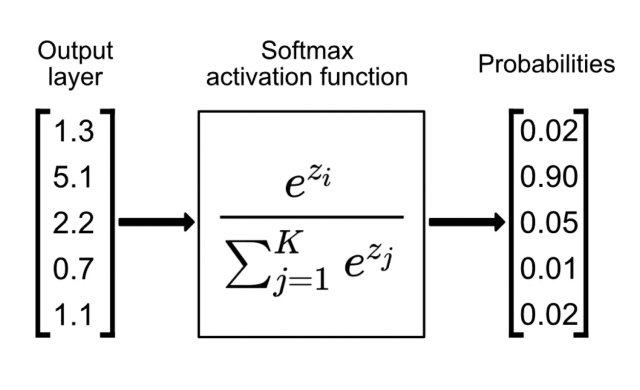

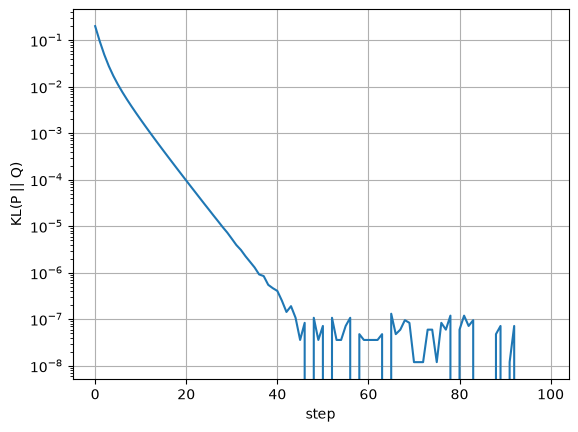

p = tensor([0.1000, 0.3000, 0.6000])
q = tensor([0.1000, 0.3000, 0.6000])


In [3]:
logits = torch.zeros(3, requires_grad=True)   # старт с равномерного
lr = 1.0
kl_values = []

for step in range(100):
    Q = torch.distributions.Categorical(logits=logits)
    kl = torch.distributions.kl_divergence(P, Q)
    kl.backward()

    with torch.no_grad():
        logits -= lr * logits.grad
    logits.grad.zero_()

    kl_values.append(kl.item())

plt.plot(kl_values)
plt.xlabel('step')
plt.ylabel('KL(P || Q)')
plt.yscale('log')
plt.grid(True)
plt.show()

print('p =', p)
print('q =', torch.softmax(logits, dim=0).detach())

---
# 4. Нейросети: `torch.nn`

## 4.1 `nn.Module` и `nn.Parameter`

Три уровня абстракции:
1. `autograd.Function` — операция со своим forward / backward
2. `nn.Module` — слой: хранит параметры (`nn.Parameter`) и описывает `forward`
3. `nn.Module` из других модулей — модель

In [4]:
# 1. Low level: операция
class MyOperation(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight):
        ctx.save_for_backward(x, weight)
        return x * weight

    @staticmethod
    def backward(ctx, grad_output):
        x, weight = ctx.saved_tensors
        grad_x = grad_output * weight
        grad_weight = (grad_output * x).sum(dim=0)  # weight общий для всего батча -> суммируем
        return grad_x, grad_weight


# 2. Mid level: слой
class MyLayer(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(input_size))

    def forward(self, x):
        return MyOperation.apply(x, self.weight)


# 3. High level: модель
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = MyLayer(10)
        self.layer2 = MyLayer(10)

    def forward(self, x):
        x = self.layer1(x)
        x = torch.relu(x)
        return self.layer2(x)


model = MyModel()
x = torch.randn(32, 10)
loss = model(x).sum()
loss.backward()

for name, p in model.named_parameters():
    print(name, p.shape, p.grad.shape)

layer1.weight torch.Size([10]) torch.Size([10])
layer2.weight torch.Size([10]) torch.Size([10])


На практике свои `Function` пишут редко: берут готовые слои (`nn.Linear`, `nn.Conv2d`, ...) и функции из `torch.nn.functional`.

`nn.Linear(in, out)` — это $y = xW^\top + b$.

In [6]:
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(10, 5)  # fully-connected
        self.fc2 = nn.Linear(5, 1)

    def forward(self, x):
        x = self.fc1(x)
        x = F.relu(x)
        return self.fc2(x)


model = SimpleNet()
print(model)

for name, param in model.named_parameters():
    print(f'{name}: {param.shape}')

SimpleNet(
  (fc1): Linear(in_features=10, out_features=5, bias=True)
  (fc2): Linear(in_features=5, out_features=1, bias=True)
)
fc1.weight: torch.Size([5, 10])
fc1.bias: torch.Size([5])
fc2.weight: torch.Size([1, 5])
fc2.bias: torch.Size([1])


### Важное наблюдение: два `nn.Linear` подряд без активации — это один `nn.Linear`

В `SimpleNet` между `fc1` и `fc2` стоит `F.relu` — нелинейность, без неё сеть теряла бы смысл.

Если бы между двумя линейными слоями не было активации, то композиция
$$y = W_2(W_1 x + b_1) + b_2 = (W_2 W_1)\,x + (W_2 b_1 + b_2) = W_{fused}\,x + b_{fused}$$
сама является линейным отображением. То есть два слоя `nn.Linear` без активации между ними математически эквивалентны одному `nn.Linear` — увеличения выразительной способности (expressivity) не происходит, только лишние параметры и вычисления.

Отсюда практический вывод: **глубина сети даёт что-то новое только вместе с нелинейностями**. Это же наблюдение используют и в обратную сторону — при оптимизации инференса (например, fusing `Linear + Linear` или `Linear + BatchNorm`) соседние линейные операции без нелинейности между ними «сливают» в одну, чтобы ускорить forward-проход.

In [7]:
class TwoLinearsNoActivation(nn.Module):
    # Два линейных слоя подряд БЕЗ активации между ними
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(10, 5)
        self.fc2 = nn.Linear(5, 1)

    def forward(self, x):
        x = self.fc1(x)
        return self.fc2(x)   # нет F.relu (или любой другой нелинейности) между слоями


torch.manual_seed(0)
unfused = TwoLinearsNoActivation()

# Слияние (fuse): W_fused = W2 @ W1, b_fused = W2 @ b1 + b2
W1, b1 = unfused.fc1.weight, unfused.fc1.bias   # W1: (5, 10), b1: (5,)
W2, b2 = unfused.fc2.weight, unfused.fc2.bias   # W2: (1, 5),  b2: (1,)

fused = nn.Linear(10, 1)
with torch.no_grad():
    fused.weight.copy_(W2 @ W1)
    fused.bias.copy_(W2 @ b1 + b2)

x = torch.rand(4, 10)
out_unfused = unfused(x)
out_fused = fused(x)

print('Совпадают:', torch.allclose(out_unfused, out_fused, atol=1e-6))
print('Макс. расхождение:', (out_unfused - out_fused).abs().max().item())
print(f'Параметров до слияния: {sum(p.numel() for p in unfused.parameters())}')
print(f'Параметров после слияния: {sum(p.numel() for p in fused.parameters())}')

Совпадают: True
Макс. расхождение: 2.9802322387695312e-08
Параметров до слияния: 61
Параметров после слияния: 11


In [8]:
x = torch.rand(4, 10)   # батч из 4 объектов
output = model(x)       # model(x) вызывает model.forward(x) + хуки; forward напрямую не вызывают
print(x.shape, '->', output.shape)

torch.Size([4, 10]) -> torch.Size([4, 1])


`nn.Parameter` — тензор, который модуль автоматически регистрирует как обучаемый параметр.

In [9]:
class SimpleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(10, 5))
        self.bias = nn.Parameter(torch.randn(5))
        self.scale = torch.ones(5)       # обычный тензор — НЕ параметр
        self.fc = nn.Linear(5, 1)

    def forward(self, x):
        x = (x @ self.weight + self.bias) * self.scale
        return self.fc(x)


for name, param in SimpleModel().named_parameters():
    print(f'{name}: {param.shape}')

weight: torch.Size([10, 5])
bias: torch.Size([5])
fc.weight: torch.Size([1, 5])
fc.bias: torch.Size([1])


## 4.2 Контейнеры и вложенность

### `nn.Sequential`

In [10]:
model_seq = nn.Sequential(
    nn.Linear(10, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
)
print(model_seq)
print(model_seq(torch.randn(5, 10)).shape)

Sequential(
  (0): Linear(in_features=10, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)
torch.Size([5, 1])


In [11]:
print([p.numel() for p in model_seq.parameters()])
print('total:', sum(p.numel() for p in model_seq.parameters()))

[640, 64, 2048, 32, 32, 1]
total: 2817


### `nn.ModuleList`

Для переменного числа слоёв. Обычный Python-список **не** зарегистрирует параметры внутри модуля.

In [12]:
class DynamicNet(nn.Module):
    def __init__(self, n_layers=3):
        super().__init__()
        self.layers = nn.ModuleList([
            nn.Linear(10 if i == 0 else 64, 64)
            for i in range(n_layers)
        ])
        self.output = nn.Linear(64, 1)

    def forward(self, x):
        for layer in self.layers:
            x = F.relu(layer(x))
        return self.output(x)


model_dynamic = DynamicNet(n_layers=5)
model_dynamic

DynamicNet(
  (layers): ModuleList(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1-4): 4 x Linear(in_features=64, out_features=64, bias=True)
  )
  (output): Linear(in_features=64, out_features=1, bias=True)
)

In [13]:
class BrokenNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = [nn.Linear(10, 10) for _ in range(3)]  # обычный list


print('ModuleList:', sum(p.numel() for p in DynamicNet(3).parameters()))
print('list:      ', sum(p.numel() for p in BrokenNet().parameters()))

ModuleList: 9089
list:       0


### `nn.ModuleDict`

In [14]:
branches = nn.ModuleDict({
    'regression': nn.Linear(10, 1),
    'classification': nn.Linear(10, 3),
})

x = torch.randn(4, 10)
for name, head in branches.items():
    print(name, head(x).shape)

regression torch.Size([4, 1])
classification torch.Size([4, 3])


### Вложенные модули

In [15]:
class Block(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.linear(x))


class BigModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.block1 = Block(10, 20)
        self.block2 = Block(20, 10)
        self.output = nn.Linear(10, 1)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        return self.output(x)


model = BigModel()
for name, p in model.named_parameters():
    print(f'{name}: {tuple(p.shape)}')
print('total:', sum(p.numel() for p in model.parameters()))

block1.linear.weight: (20, 10)
block1.linear.bias: (20,)
block2.linear.weight: (10, 20)
block2.linear.bias: (10,)
output.weight: (1, 10)
output.bias: (1,)
total: 441


---
# 5. Обучение

## 5.1 Полный цикл на линейной регрессии

Данные: $y = 2x + 0.5 + \varepsilon$.

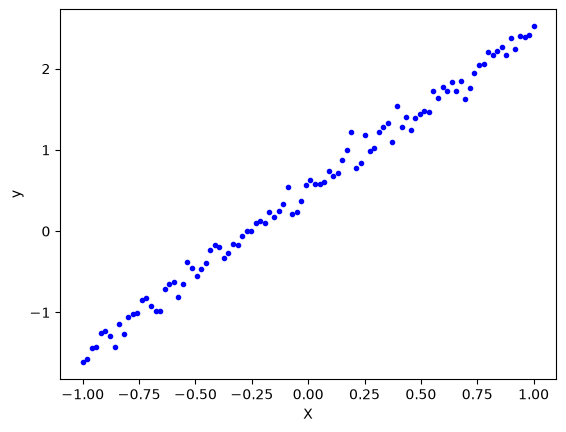

In [16]:
torch.manual_seed(0)
n_samples = 100
X = torch.linspace(-1, 1, n_samples).reshape(-1, 1)
y = 2 * X + 0.5 + 0.1 * torch.randn(X.size())

plt.plot(X, y, 'b.')
plt.xlabel('X')
plt.ylabel('y')
plt.show()

In [17]:
class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)


model = LinearRegression()
print(f'w = {model.linear.weight.item():.4f}')
print(f'b = {model.linear.bias.item():.4f}')

w = -0.2489
b = 0.0451


Нужны ещё две вещи:
- **loss** (`torch.nn`): `nn.MSELoss`, `nn.L1Loss`, `nn.CrossEntropyLoss`, `nn.BCEWithLogitsLoss`, ...
- **оптимизатор** (`torch.optim`): `SGD`, `Adam`, `AdamW`, ... — получает параметры модели и обновляет их по `.grad`

In [18]:
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

print(optimizer)
print(criterion(torch.tensor([1., 2., 3.]), torch.tensor([2., 2., 3.])))  # (1 + 0 + 0) / 3

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.1
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)
tensor(0.3333)


Цикл обучения — одни и те же 5 строк в любом проекте:
1. forward: `y_pred = model(X)`
2. loss: `loss = criterion(y_pred, y)`
3. `optimizer.zero_grad()` — обнулить накопленные градиенты
4. `loss.backward()` — посчитать новые
5. `optimizer.step()` — обновить параметры: $w \leftarrow w - lr \cdot \nabla_w L$

In [19]:
losses = []
n_epochs = 100

for epoch in range(n_epochs):
    y_pred = model(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch + 1:>3}/{n_epochs}], Loss: {loss.item():.4f}')

Epoch [ 10/100], Loss: 0.4983
Epoch [ 20/100], Loss: 0.1288
Epoch [ 30/100], Loss: 0.0394
Epoch [ 40/100], Loss: 0.0176
Epoch [ 50/100], Loss: 0.0122
Epoch [ 60/100], Loss: 0.0109
Epoch [ 70/100], Loss: 0.0106
Epoch [ 80/100], Loss: 0.0105
Epoch [ 90/100], Loss: 0.0105
Epoch [100/100], Loss: 0.0105


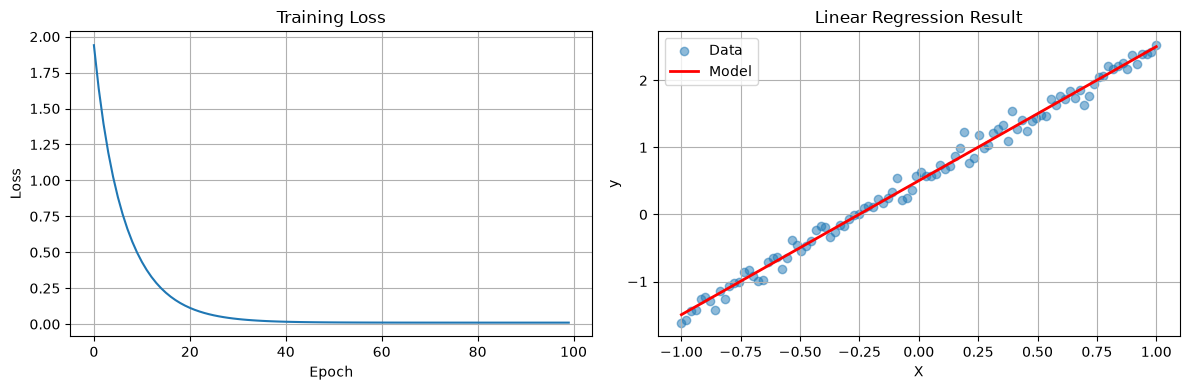

Weight: 1.998 (expected ~2.0)
Bias:   0.504 (expected ~0.5)


In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(losses)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Training Loss')
ax1.grid(True)

with torch.no_grad():
    y_pred = model(X)

ax2.scatter(X, y, alpha=0.5, label='Data')
ax2.plot(X, y_pred, 'r-', linewidth=2, label='Model')
ax2.set_xlabel('X')
ax2.set_ylabel('y')
ax2.set_title('Linear Regression Result')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

print(f'Weight: {model.linear.weight.item():.3f} (expected ~2.0)')
print(f'Bias:   {model.linear.bias.item():.3f} (expected ~0.5)')

## 5.2 `Dataset` и `DataLoader`

- `Dataset` — знает, сколько объектов (`__len__`) и как достать $i$-й (`__getitem__`)
- `DataLoader` — нарезает датасет на батчи, перемешивает, может грузить данные в несколько процессов

In [21]:
torch.manual_seed(0)
n_samples = 1000
X = torch.randn(n_samples, 10)
y = (X[:, 0] * 2 + X[:, 1] * 0.5 + torch.randn(n_samples) * 0.1).unsqueeze(1)

n_train = int(0.8 * n_samples)
X_train, X_val = X[:n_train], X[n_train:]
y_train, y_val = y[:n_train], y[n_train:]

print(f'Train size: {X_train.shape[0]}')
print(f'Val size:   {X_val.shape[0]}')

Train size: 800
Val size:   200


Свой `Dataset` — два метода:

In [22]:
class MyDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        # здесь обычно читают картинку с диска, токенизируют текст и т.п.
        return self.X[idx], self.y[idx]


ds = MyDataset(X_train, y_train)
print(len(ds))
x0, y0 = ds[0]
print(x0.shape, y0.shape)

800
torch.Size([10]) torch.Size([1])


Для данных, которые уже лежат в тензорах, есть готовый `TensorDataset`:

In [23]:
batch_size = 32

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print(f'Number of train batches: {len(train_loader)}')
print(f'Number of val batches:   {len(val_loader)}')

batch_X, batch_y = next(iter(train_loader))
print(f'Batch shape: X={batch_X.shape}, y={batch_y.shape}')

Number of train batches: 25
Number of val batches:   7
Batch shape: X=torch.Size([32, 10]), y=torch.Size([32, 1])


## 5.3 Train / val цикл

In [24]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0
    for batch_X, batch_y in loader:
        optimizer.zero_grad()
        loss = criterion(model(batch_X), batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch_X.size(0)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def val_epoch(model, loader, criterion):
    model.eval()
    total_loss = 0
    for batch_X, batch_y in loader:
        loss = criterion(model(batch_X), batch_y)
        total_loss += loss.item() * batch_X.size(0)
    return total_loss / len(loader.dataset)

In [25]:
torch.manual_seed(0)
model = nn.Sequential(
    nn.Linear(10, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

train_losses, val_losses = [], []
n_epochs = 50

for epoch in range(n_epochs):
    train_losses.append(train_epoch(model, train_loader, criterion, optimizer))
    val_losses.append(val_epoch(model, val_loader, criterion))

    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch + 1}/{n_epochs}: Train Loss = {train_losses[-1]:.4f}, Val Loss = {val_losses[-1]:.4f}')

Epoch 10/50: Train Loss = 0.0326, Val Loss = 0.0298
Epoch 20/50: Train Loss = 0.0174, Val Loss = 0.0257
Epoch 30/50: Train Loss = 0.0134, Val Loss = 0.0232
Epoch 40/50: Train Loss = 0.0106, Val Loss = 0.0218
Epoch 50/50: Train Loss = 0.0091, Val Loss = 0.0221


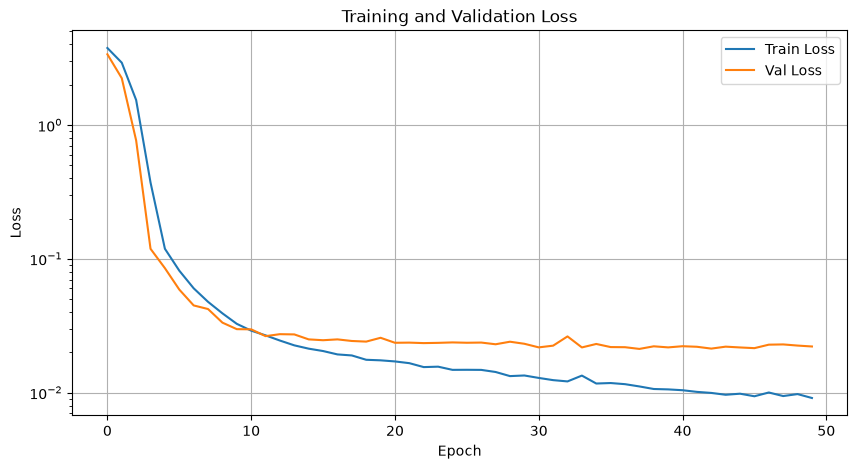

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.yscale('log')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

## 5.4 Обучение на GPU

Модель и данные должны лежать на одном устройстве: `model.to(device)` переносит все параметры, батчи переносим внутри цикла.

In [30]:
model = model.to(device)
batch_X, batch_y = next(iter(train_loader))
batch_X, batch_y = batch_X.to(device), batch_y.to(device)

print(next(model.parameters()).device, batch_X.device)
print(criterion(model(batch_X), batch_y))

model = model.to('cpu')

cuda:0 cuda:0
tensor(0.0057, device='cuda:0', grad_fn=<MseLossBackward0>)


---
# 6. Режимы модели: `train()` и `eval()`

Некоторые слои ведут себя по-разному при обучении и при инференсе. Переключает их `model.train()` / `model.eval()`.

## 6.1 Dropout

При обучении зануляет каждый элемент с вероятностью $p$, а оставшиеся умножает на $\frac{1}{1-p}$, чтобы матожидание не изменилось. В eval — ничего не делает.

In [31]:
dropout = nn.Dropout(p=0.5)
x = torch.ones(1, 20)

dropout.train()
print('train:', dropout(x)[0])

dropout.eval()
print('eval: ', dropout(x)[0])

train: tensor([2., 0., 0., 0., 2., 0., 0., 2., 0., 0., 2., 0., 2., 2., 2., 0., 2., 2.,
        2., 2.])
eval:  tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1.])


## 6.2 BatchNorm

В train нормирует по статистикам **текущего батча** и копит скользящее среднее; в eval использует накопленные статистики.
Поэтому батч из одного объекта в train-режиме — ошибка.

In [32]:
class NormalizedNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(10, 64)
        self.bn1 = nn.BatchNorm1d(64)
        self.fc2 = nn.Linear(64, 32)
        self.bn2 = nn.BatchNorm1d(32)
        self.fc3 = nn.Linear(32, 1)

    def forward(self, x):
        x = F.relu(self.bn1(self.fc1(x)))
        x = F.relu(self.bn2(self.fc2(x)))
        return self.fc3(x)


model_bn = NormalizedNet()
print(model_bn)

NormalizedNet(
  (fc1): Linear(in_features=10, out_features=64, bias=True)
  (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (bn2): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
)


In [35]:
x = torch.randn(1, 10)

model_bn.train()
try:
    model_bn(x)
except ValueError as e:
    print('train:', e)

model_bn.eval()
print('eval: ', model_bn(x))

train: Expected more than 1 value per channel when training, got input size torch.Size([1, 64])
eval:  tensor([[0.1322]], grad_fn=<AddmmBackward0>)


In [36]:
# running-статистики — это буферы: они сохраняются в state_dict, но не обучаются градиентом
for name, buf in model_bn.bn2.named_buffers():
    print(name, tuple(buf.shape))

running_mean (32,)
running_var (32,)
num_batches_tracked ()


## 6.3 `torch.no_grad()` vs `torch.inference_mode()`

На инференсе граф не нужен. Оба контекста отключают его построение: не сохраняются промежуточные активации для backward, поэтому главный выигрыш — **память** (можно брать батч больше). По времени forward разница обычно небольшая.
`inference_mode` ещё агрессивнее: тензоры из него вообще нельзя потом использовать в autograd.

In [37]:
big_model = nn.Sequential(
    nn.Linear(1000, 1000), nn.ReLU(),
    nn.Linear(1000, 1000), nn.ReLU(),
    nn.Linear(1000, 1000), nn.ReLU(),
    nn.Linear(1000, 1000),
).to(device)
x = torch.randn(512, 1000, device=device)


def saved_for_backward_mb(fn):
    # Считаем, сколько тензоров autograd сохранил для backward
    total = 0

    def pack(t):
        nonlocal total
        total += t.numel() * t.element_size()
        return t

    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        fn()
    return total / 2**20


print(f'Normal:         {saved_for_backward_mb(lambda: big_model(x)):.1f} MB')
with torch.no_grad():
    print(f'no_grad:        {saved_for_backward_mb(lambda: big_model(x)):.1f} MB')
with torch.inference_mode():
    print(f'inference_mode: {saved_for_backward_mb(lambda: big_model(x)):.1f} MB')

Normal:         25.1 MB
no_grad:        0.0 MB
inference_mode: 0.0 MB


### Сводная таблица

| | обычный режим | `torch.no_grad()` | `torch.inference_mode()` |
|---|---|---|---|
| Строится граф (`grad_fn`) | ✅ | ❌ | ❌ |
| Сохраняются активации для backward | ✅ | ❌ | ❌ |
| `requires_grad` результата | как у входа | `False` | `False` |
| `is_inference()` результата | `False` | `False` | `True` |
| Можно потом `.requires_grad_(True)` и включить в граф | ✅ | ✅ | ❌ (ошибка) |
| Version counter (отслеживание in-place изменений) | включён | включён | отключён |
| Накладные расходы на forward | базовые | чуть меньше | минимальные |

**Вывод:** для чистого инференса используйте `inference_mode` — он строже и немного быстрее. `no_grad` нужен, если результат может понадобиться снова "включить" в граф автограда или для совместимости со старым кодом.

In [38]:
with torch.no_grad():
    a = big_model(x)
with torch.inference_mode():
    b = big_model(x)

print('requires_grad:', a.requires_grad, b.requires_grad)
print('is_inference: ', a.is_inference(), b.is_inference())

requires_grad: False False
is_inference:  False True


---
# 7. Предсказание неопределённости

Точечного предсказания часто мало — хочется знать, насколько модель уверена. Возьмём данные, где шум зависит от $x$ (гетероскедастичность):
$$y = x^2 + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, \sigma(x)^2), \quad \sigma(x) = 0.5 + 0.3 x^2$$

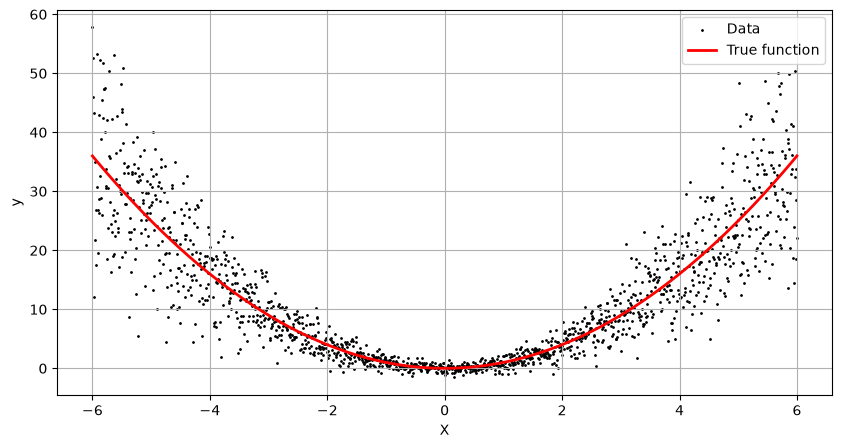

In [39]:
torch.manual_seed(42)
n = 1500
X_data = torch.linspace(-6, 6, n).unsqueeze(1)   # (n, 1)
y_true = X_data ** 2                             # (n, 1)

noise_std = 0.5 + 0.3 * X_data ** 2
y_data = y_true + noise_std * torch.randn(n, 1)

plt.figure(figsize=(10, 5))
plt.scatter(X_data, y_data, s=1, color='k', label='Data')
plt.plot(X_data, y_true, 'r-', label='True function', linewidth=2)
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

## 7.1 Предсказываем параметры распределения

Пусть сеть выдаёт не число, а параметры нормального распределения $\mu(x)$ и $\log\sigma^2(x)$ (логарифм — чтобы дисперсия была положительной).
Обучаем максимизацией правдоподобия, то есть минимизируем **negative log-likelihood**:
$$-\log p(y \mid x) = \frac{1}{2}\left(\log 2\pi + \log\sigma^2 + \frac{(y - \mu)^2}{\sigma^2}\right)$$

MSE — частный случай этого при фиксированной $\sigma$.

In [40]:
class GaussianNet(nn.Module):
    # Предсказывает параметры гауссовского распределения
    def __init__(self):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(1, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
        )
        # Две головы: для mu и для log(sigma^2)
        self.mu_head = nn.Linear(64, 1)
        self.logvar_head = nn.Linear(64, 1)

    def forward(self, x):
        features = self.shared(x)
        return self.mu_head(features), self.logvar_head(features)


def nll_loss(mu, logvar, y):
    # константа log(2 pi) не влияет на градиент — выбрасываем
    return 0.5 * (logvar + (y - mu) ** 2 / logvar.exp()).mean()


torch.manual_seed(0)
model_gauss = GaussianNet()
model_gauss

GaussianNet(
  (shared): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
  )
  (mu_head): Linear(in_features=64, out_features=1, bias=True)
  (logvar_head): Linear(in_features=64, out_features=1, bias=True)
)

Тот же лосс можно получить из раздела 3 — через `torch.distributions.Normal`:

In [41]:
with torch.no_grad():
    mu, logvar = model_gauss(X_data)
    dist = torch.distributions.Normal(mu, torch.exp(0.5 * logvar))
    nll_dist = -dist.log_prob(y_data).mean()

    print(nll_loss(mu, logvar, y_data) + 0.5 * np.log(2 * np.pi))
    print(nll_dist)

tensor(177.4107)
tensor(177.4106)


Epoch 200: Loss = 1.5774
Epoch 400: Loss = 1.5130
Epoch 600: Loss = 1.5008
Epoch 800: Loss = 1.4987
Epoch 1000: Loss = 1.4968


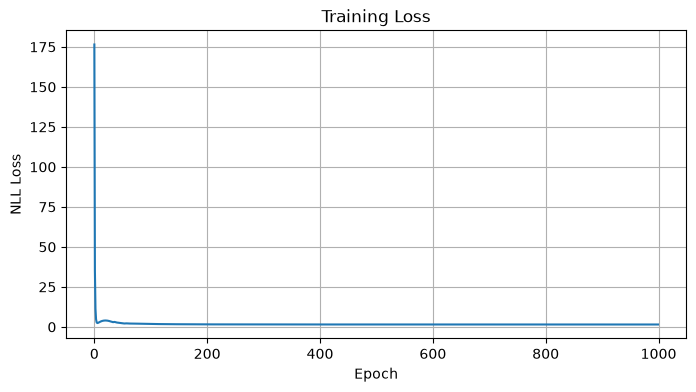

In [42]:
optimizer = torch.optim.Adam(model_gauss.parameters(), lr=0.01)
losses = []

for epoch in range(1000):
    mu, logvar = model_gauss(X_data)
    loss = nll_loss(mu, logvar, y_data)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    if (epoch + 1) % 200 == 0:
        print(f'Epoch {epoch + 1}: Loss = {loss.item():.4f}')

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel('Epoch')
plt.ylabel('NLL Loss')
plt.title('Training Loss')
plt.grid(True)
plt.show()

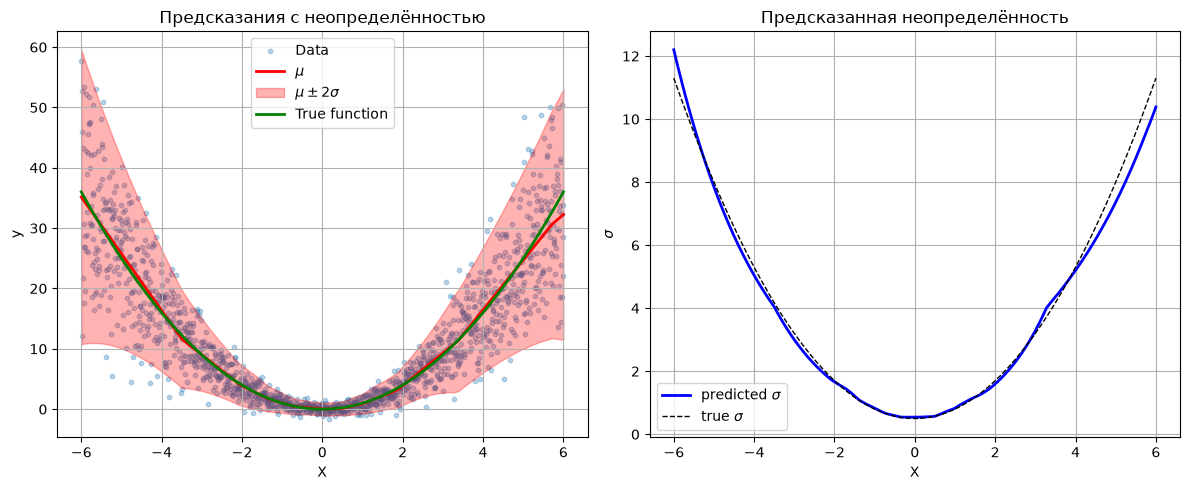

In [43]:
model_gauss.eval()
with torch.no_grad():
    mu_pred, logvar_pred = model_gauss(X_data)
    sigma_pred = torch.exp(0.5 * logvar_pred)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_data, y_data, alpha=0.3, label='Data', s=10)
plt.plot(X_data, mu_pred, 'r-', label=r'$\mu$', linewidth=2)
plt.fill_between(
    X_data.squeeze(),
    (mu_pred - 2 * sigma_pred).squeeze(),
    (mu_pred + 2 * sigma_pred).squeeze(),
    alpha=0.3, color='red', label=r'$\mu \pm 2\sigma$',
)
plt.plot(X_data, y_true, 'g-', label='True function', linewidth=2)
plt.xlabel('X')
plt.ylabel('y')
plt.title('Предсказания с неопределённостью')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(X_data, sigma_pred, 'b-', linewidth=2, label=r'predicted $\sigma$')
plt.plot(X_data, noise_std, 'k--', linewidth=1, label=r'true $\sigma$')
plt.xlabel('X')
plt.ylabel(r'$\sigma$')
plt.title('Предсказанная неопределённость')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 7.2 MC Dropout

Другой источник неопределённости — неуверенность **самой модели** (эпистемическая), а не шум в данных (алеаторная).

Идея: оставить dropout включённым на инференсе и сделать много forward-проходов. Каждый проход — немного другая «подсеть»; разброс их предсказаний показывает, насколько модель уверена.

In [44]:
class MCDropoutNet(nn.Module):
    def __init__(self, dropout_rate=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 64), nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(64, 64), nn.ReLU(), nn.Dropout(dropout_rate),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.net(x)

    @torch.no_grad()
    def predict_with_uncertainty(self, x, n_samples=100):
        self.train()  # ВАЖНО: dropout должен остаться включённым
        preds = torch.stack([self(x) for _ in range(n_samples)])  # (n_samples, n, 1)
        return preds.mean(dim=0), preds.std(dim=0)


torch.manual_seed(0)
model_mc = MCDropoutNet(dropout_rate=0.1)
optimizer = torch.optim.Adam(model_mc.parameters(), lr=0.01)

model_mc.train()
for epoch in range(500):
    loss = F.mse_loss(model_mc(X_data), y_data)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print(f'Final MSE: {loss.item():.4f}')

Final MSE: 29.1773


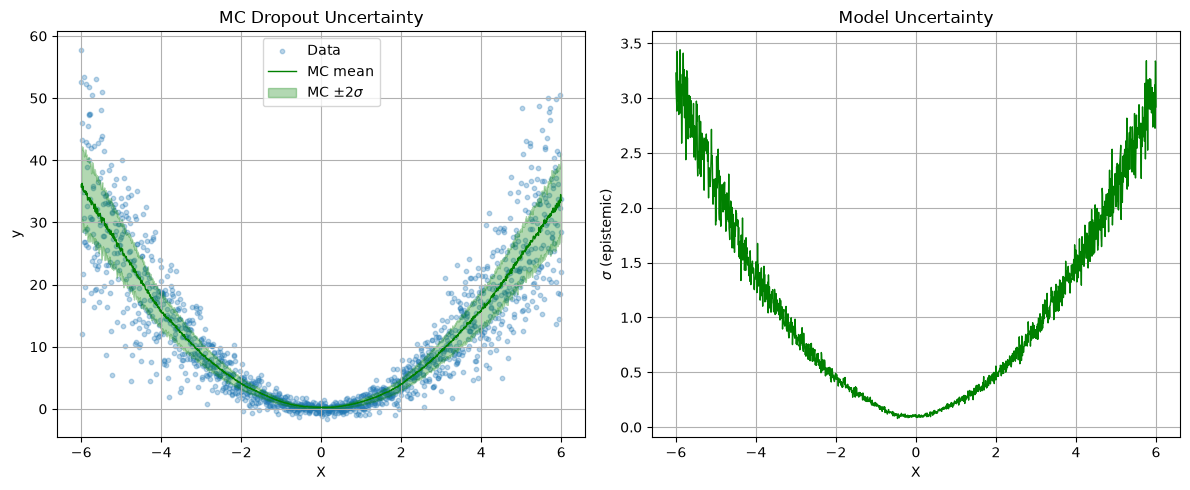

In [ ]:
mean_mc, std_mc = model_mc.predict_with_uncertainty(X_data, n_samples=100)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_data, y_data, alpha=0.3, label='Data', s=10)
plt.plot(X_data, mean_mc, 'g-', label='MC mean', linewidth=1)
plt.fill_between(
    X_data.squeeze(),
    (mean_mc - 2 * std_mc).squeeze(),
    (mean_mc + 2 * std_mc).squeeze(),
    alpha=0.3, color='green', label=r'MC $\pm 2\sigma$',
)
plt.xlabel('X')
plt.ylabel('y')
plt.title('MC Dropout Uncertainty') 
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(X_data, std_mc, 'g-', linewidth=1)
plt.xlabel('X')
plt.ylabel(r'$\sigma$ (epistemic)')
plt.title('Model Uncertainty')
plt.grid(True)

plt.tight_layout()
plt.show()

Сравните: гауссовская голова выучила **шум в данных** (растёт как $0.5 + 0.3x^2$), а MC Dropout показывает **неуверенность модели** 